# Imports

In [34]:
# %pip install tensorflow
# %pip install tensorboard
# %pip install --upgrade tensorflow keras
# %pip install keras_tuner
# %pip install huggingface_hub
# %pip install datasets
# %pip install ipywidgets

In [44]:
import os
import re
import glob
import json
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
import keras_tuner as kt

RANDOM_STATE = 1234

# Import & View data

In [ ]:
#TODO really need to make sure there is no per-sample data leakage in the train/val/test splits. This means that if a vial has multiple captures, all of them should be in the same split. The current implementation does not guarantee this.
#perhaps an assert statement at some point in this function would do the trick. 

def load_npz_dataframe(
    data_dir="data/", 
    metadata_path="vial_metadata.json", 
    task_type='multi',
    train_size=0.7, 
    val_size=0.20, 
    test_size=0.10
):    
    """
    Scans the data directory, reads the JSON registry, dynamically maps 
    encountered species to integer labels, and handles small-batch splitting.
    """
    assert abs((train_size + val_size + test_size) - 1.0) < 1e-5, "Split proportions must sum to 1.0"
    with open(metadata_path, 'r', encoding='utf-8') as f:
        vial_registry = json.load(f)
        
    files = glob.glob(os.path.join(data_dir, "*.npz"))
    data = []
    for f in files:
        file_name = os.path.basename(f)
        parts = file_name.split('_')
        vial_number, sample_letter, capture_number = parts[0], parts[1], parts[2].replace(".npz", "")
        if len(parts) < 3:
            print(f"Warning: Unexpected filename format for {file_name}. Skipping.")
            continue
        if vial_number in vial_registry:
            species_id = vial_registry[vial_number].get("Species ID")
            data.append({
                "filepath": f, 
                "vial": vial_number,
                "sample": sample_letter,
                "capture": capture_number,
                "species": species_id
            })
                
    df = pd.DataFrame(data)        
    unique_species = df['species'].unique()
    number_of_species = len(unique_species)
    species_to_label = {species: i for i, species in enumerate(unique_species)}
    df['label'] = df['species'].map(species_to_label)
    
    min_class_count = df['label'].value_counts().min()
    use_stratify = df['label'] if min_class_count >= 4 else None
    if use_stratify is None:
        print("Notice: Class counts too low for stratification. Using random split.")
    
    # Split 1: Separate Train from (Val + Test)
    temp_size = val_size + test_size
    train_df, temp_df = train_test_split(
        df, test_size=temp_size, stratify=use_stratify, random_state=RANDOM_STATE
    )

    # Split 2: Separate Val from Test
    temp_min = temp_df['label'].value_counts().min()
    use_stratify_temp = temp_df['label'] if (use_stratify is not None and temp_min >= 2) else None
    
    # Calculate what fraction of the temp_df needs to go to the test set
    test_fraction_of_temp = test_size / temp_size
    val_df, test_df = train_test_split(
        temp_df, test_size=test_fraction_of_temp, stratify=use_stratify_temp, random_state=RANDOM_STATE
    )
    num_classes = 1 if task_type == 'binary' else number_of_species
    print(f"Loaded {len(train_df)} train, {len(val_df)} val, and {len(test_df)} test samples. Task: {task_type}")
    return train_df, val_df, test_df, num_classes

In [40]:
# method 0: just take all the rgb channels 

# method 1: take the average of the rgb channels
def collapse_average(img_array):
    """Calculates the raw unweighted mean across the 3 color channels. Simplest form of monochrome collapse."""
    return np.mean(img_array, axis=-1)

# method 2: take a weighted average based on channel intensity so that weak channels are given less weight, as they are more likely to be noise
def collapse_sensitivity_aware(img_array):
    """Calculates a weighted monochrome collapse based on channel intensity. Very similar to the average just with a weighting based on brightness of each channel."""
    channel_intensities = np.mean(img_array, axis=(0, 1))
    total_intensity = np.sum(channel_intensities)
    weights = channel_intensities / total_intensity
    print(f"Channel intensities: {channel_intensities}; Weights: {weights}")
    return np.dot(img_array, weights)

# method 3: take a weighted average based on the physical sensor profile for the specific wavelength of the LED illuminating the frame
with open('imx571_spectral_profile.json', 'r') as f:
    sensor_profile = json.load(f)

def get_profile_weights(wavelength_nm):
    """Looks up the normalized RGB response weights for a specific wavelength."""
    min_w = sensor_profile['min_wavelength']
    max_w = sensor_profile['max_wavelength']
    w = max(min_w, min(int(wavelength_nm), max_w))
    idx = w - min_w
    r = sensor_profile['normalized_response']['R'][idx]
    g = sensor_profile['normalized_response']['G'][idx]
    b = sensor_profile['normalized_response']['B'][idx]
    total = r + g + b
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return np.array([r/total, g/total, b/total])

def collapse_profile_aware(img_array, band_name):
    """
    Collapses the RGB channels using the physical sensor profile weights 
    for the specific LED wavelength illuminating the frame.
    """
    match = re.search(r'_(\d+)nm', band_name)# extract the wavelength from strings like "Band 8_640nm_R"
    if not match:
        raise ValueError(f"Could not extract wavelength from band name: {band_name}")
    wavelength = int(match.group(1))
    weights = get_profile_weights(wavelength)
    return np.dot(img_array, weights)

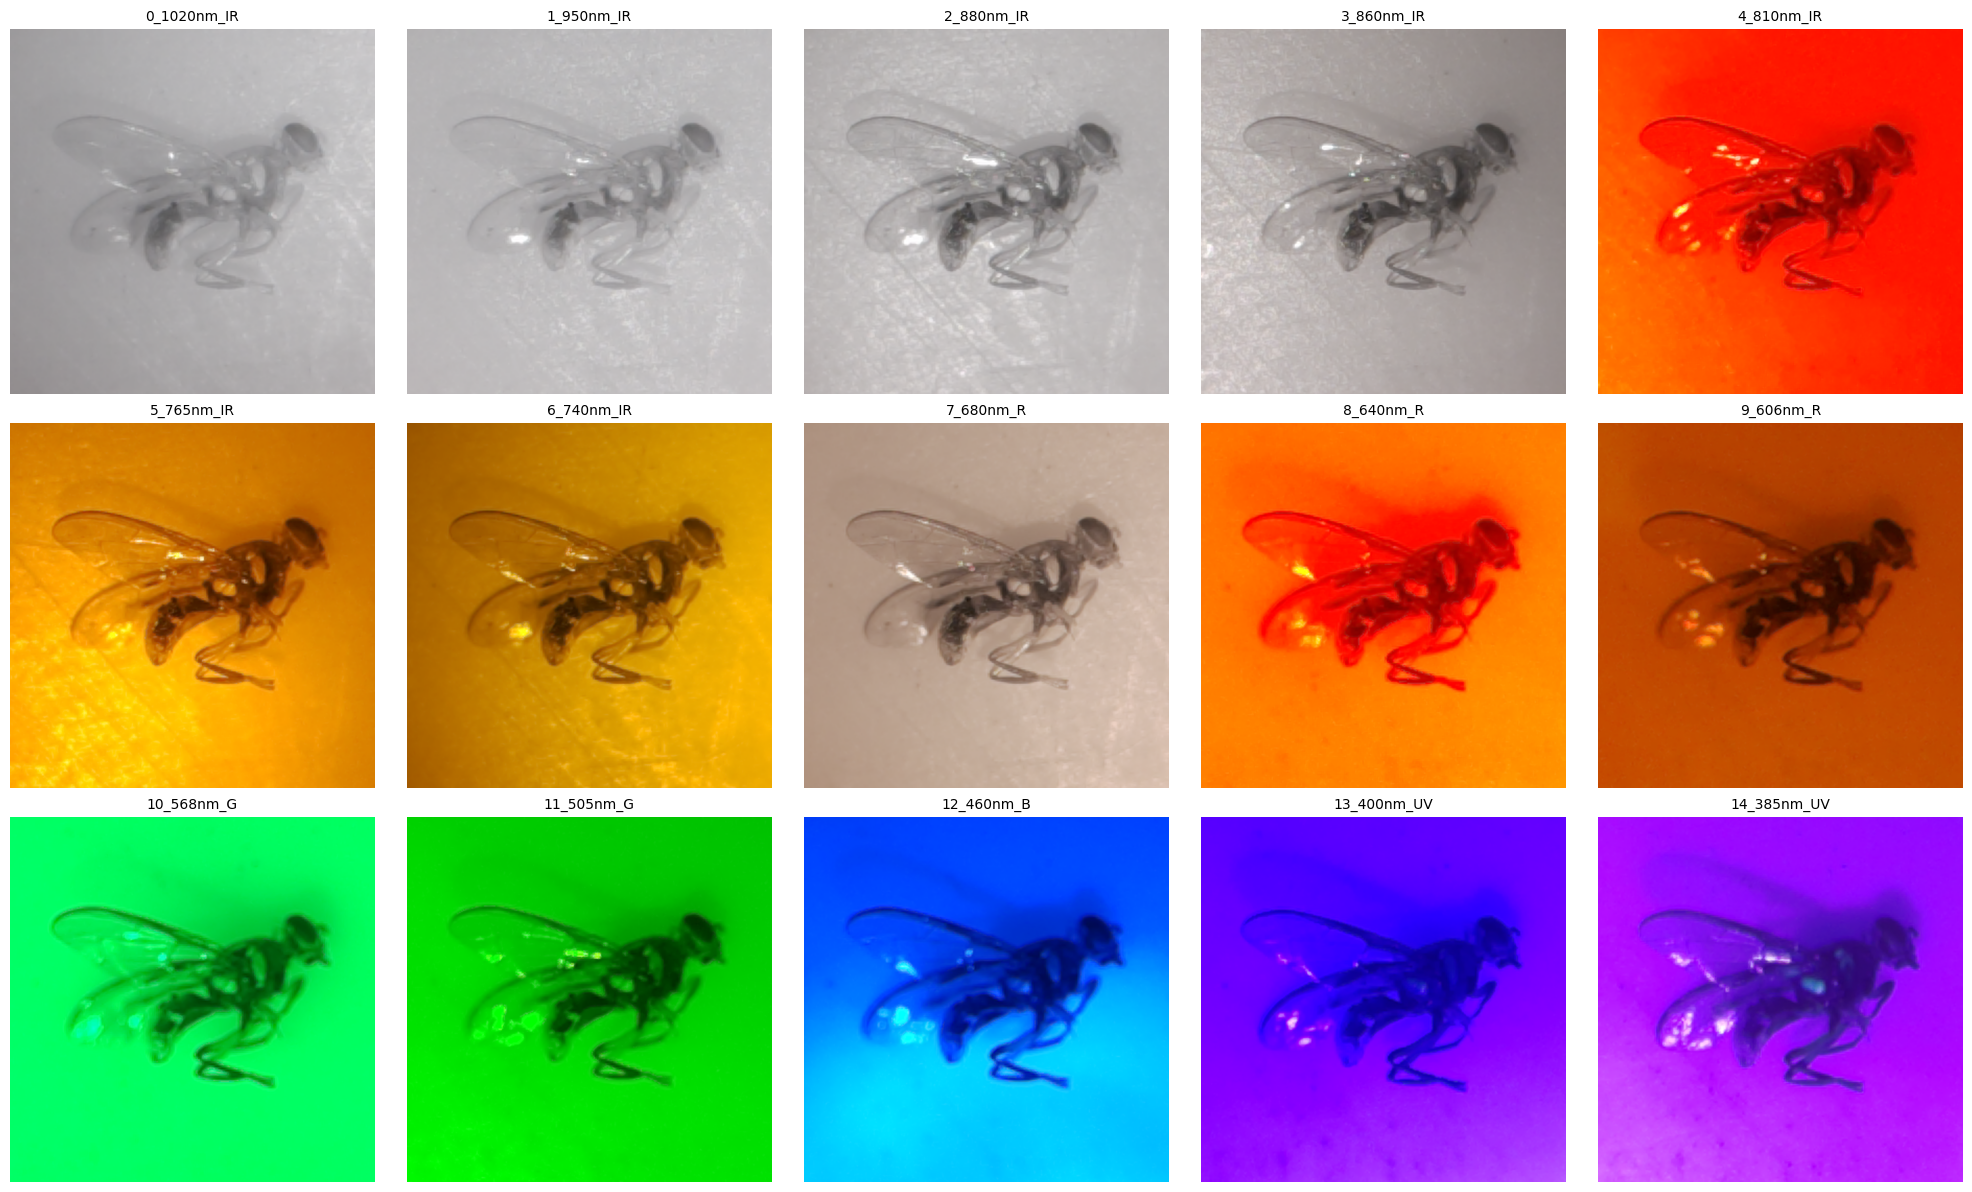

In [41]:
def static_cube_grid(filepath, collapse_method=None):
    with np.load(filepath, allow_pickle=True) as data:
        img_cube = data['data']
        bands = data['bands']
        
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()
    
    for i in range(15):
        band_slice = img_cube[:, :, :, i]
        band_name = bands[i]
        
        if collapse_method is None:
            # Leave as raw RGB (BGR to RGB fix applied)
            display_img = band_slice
            cmap = None
        else:
            # Pass BOTH the image array and the band name to the custom function
            display_img = collapse_method(band_slice, band_name)
            cmap = 'gray'
            
        axes[i].imshow(display_img, cmap=cmap)
        axes[i].set_title(band_name, fontsize=10)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

static_cube_grid(train_df.iloc[0]['filepath'], collapse_method=None)

# Tensorflow Loader

In [46]:
# 2. Build the multispectral tf.data pipeline
def create_tf_dataset(df, simulate_rgb=False, batch_size=32, img_size=(224, 224), is_training=False):
    paths = df['filepath'].values
    labels = df['label'].values
    final_channels = 3 if simulate_rgb else 45
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    def load_npz_image(path, label):
        def _load_numpy(file_path):
            with np.load(file_path.decode('utf-8'), allow_pickle=True) as data:
                img = data['data'] 
            
            h, w, colors, bands = img.shape
            if simulate_rgb:
                # Assuming PiCam saves in BGR order (Blue=0, Green=1, Red=2)
                # Band 7 = 680nm(R), Band 10 = 568nm(G), Band 12 = 460nm(B)
                r_channel = img[:, :, 2, 7]
                g_channel = img[:, :, 1, 10]
                b_channel = img[:, :, 0, 12]
                img_final = np.stack([r_channel, g_channel, b_channel], axis=-1)
            else:
                img_final = img.reshape(h, w, colors * bands)
                
            return img_final.astype(np.float32) / 255.0

        img = tf.numpy_function(_load_numpy, [path], tf.float32)
        img.set_shape((700, 700, final_channels))
        img = tf.image.resize(img, img_size)
        return img, label
        
    ds = ds.map(load_npz_image, num_parallel_calls=tf.data.AUTOTUNE)
    if is_training:
        ds = ds.shuffle(buffer_size=len(df))
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

In [47]:
TASK_TYPE = 'binary'  # Options: 'binary' or 'multi'
SIMULATE_RGB = False  # Options: True or False

train_df, val_df, test_df, num_classes = load_npz_dataframe(task_type=TASK_TYPE)

train_dataset = create_tf_dataset(train_df, simulate_rgb=SIMULATE_RGB, is_training=True)
val_dataset = create_tf_dataset(val_df, simulate_rgb=SIMULATE_RGB)
test_dataset = create_tf_dataset(test_df, simulate_rgb=SIMULATE_RGB)

Loaded 6 train, 2 val, and 2 test samples. Task: binary


# Model Builder & Training

In [48]:
# Define L1 Layer (Ensure it's serializable)
@keras.saving.register_keras_serializable()
class SpectralSelectionLayer(layers.Layer):
    def __init__(self, num_channels=45, l1_penalty=1e-3, **kwargs):
        super().__init__(**kwargs)
        self.l1_penalty = l1_penalty
        self.num_channels = num_channels

    def build(self, input_shape):
        self.channel_weights = self.add_weight(
            name='channel_weights',
            shape=(1, 1, 1, self.num_channels),
            initializer='ones',
            trainable=True,
            regularizer=keras.regularizers.L1(self.l1_penalty)
        )

    def call(self, inputs):
        return inputs * self.channel_weights
        
    def get_config(self):
        config = super().get_config()
        config.update({"num_channels": self.num_channels, "l1_penalty": self.l1_penalty})
        return config

# Higher-order function to inject modular settings into the Keras Tuner
def get_model_builder(task_type, simulate_rgb, num_classes):
    def model_builder(hp):
        model = keras.Sequential()
        
        # 1. Input Layer
        input_channels = 3 if simulate_rgb else 45
        model.add(layers.Input(shape=(224, 224, input_channels)))
        
        # 2. Data Augmentation
        model.add(layers.RandomFlip("horizontal_and_vertical"))
        model.add(layers.RandomRotation(0.2))
        
        # 3. Feature Selection (Only apply if using multispectral array)
        if not simulate_rgb:
            l1_rate = hp.Choice('l1_penalty', [1e-2, 1e-3, 1e-4])
            model.add(SpectralSelectionLayer(num_channels=45, l1_penalty=l1_rate))
        
        # 4. Convolutional Blocks
        model.add(layers.Conv2D(
            filters=hp.Int('filters1', 32, 128, step=16),
            kernel_size=hp.Choice('kernel1', [3, 5]),
            activation='relu', padding='same'
        ))
        if hp.Choice("layer_1_pool", ["max", "avg"]) == "max":
            model.add(layers.MaxPooling2D())
        else:
            model.add(layers.AveragePooling2D(pool_size=(2, 2)))
            
        model.add(layers.Flatten())
        model.add(layers.Dense(units=hp.Int('dense_units', 64, 256, step=32), activation='relu'))
        if hp.Boolean('use_dropout'):
            model.add(layers.Dropout(hp.Float('dropout', 0.1, 0.5)))

        # 5. Modular Output Layer
        if task_type == 'binary':
            model.add(layers.Dense(1, activation='sigmoid'))
            loss_fn = 'binary_crossentropy'
            # Note: For binary, we track accuracy, precision, and recall
            metrics = ['accuracy', keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
        else:
            model.add(layers.Dense(num_classes, activation='softmax'))
            loss_fn = 'sparse_categorical_crossentropy'
            metrics = ['accuracy']

        # Compile
        lr = hp.Float('lr', 1e-5, 1e-2, sampling='log')
        model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss_fn, metrics=metrics)
        return model
        
    return model_builder

In [49]:
TASK_TYPE = 'binary'  # Options: 'binary' or 'multi'
SIMULATE_RGB = False  # Options: True or False

train_df, val_df, test_df, num_classes = load_npz_dataframe(task_type=TASK_TYPE)

train_dataset = create_tf_dataset(train_df, simulate_rgb=SIMULATE_RGB, is_training=True)
val_dataset = create_tf_dataset(val_df, simulate_rgb=SIMULATE_RGB)
test_dataset = create_tf_dataset(test_df, simulate_rgb=SIMULATE_RGB)

# Initialize Tuner
tuner = kt.Hyperband(
    get_model_builder(TASK_TYPE, SIMULATE_RGB, num_classes),
    objective='val_accuracy',
    max_epochs=20,
    factor=3,
    directory='tuning_results',
    project_name=f"{TASK_TYPE}_{'rgb' if SIMULATE_RGB else 'msi'}"
)

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Run the search
tuner.search(train_dataset, validation_data=val_dataset, epochs=20, callbacks=[early_stop], verbose=1)

# Extract and train the best model
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
final_model = tuner.hypermodel.build(best_hps)
history = final_model.fit(train_dataset, validation_data=val_dataset, epochs=50, callbacks=[early_stop])

# Evaluate against the untouched test set
results = final_model.evaluate(test_dataset)
print(f"Test Set Evaluation Metrics: {results}")

Trial 30 Complete [00h 00m 18s]
val_accuracy: 0.5

Best val_accuracy So Far: 1.0
Total elapsed time: 00h 41m 24s
Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.7168 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 38.6851 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 39.4081 - precision: 0.5000 - recall: 1.0000 - val_accuracy: 0.5000 - val_loss: 16.0386 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 15.4434 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 9.6442 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 9.2668 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 2.2659 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/50
1/1 